### Proyek analisis data : bike sharing dataset
- Nama : Primo Putra Ramadhan
- Email :putraramadhan1710@gmail.com
- ID DICODING : primoput

## Menentukan Pertanyaan Bisnis
1. Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per hari berdasarkan kondisi cuaca dan musim sepanjang tahun 2011–2012, sebagai dasar penentuan jadwal pemeliharaan (maintenance) armada dan strategi promosi pada periode sepi penyewa?
2. Pada rentang jam berapa terjadi puncak rata-rata penyewaan sepeda per jam antara pengguna casual dan registered pada hari kerja dibandingkan hari libur sepanjang tahun 2011–2012, sebagai dasar pengaturan alokasi distribusi sepeda di stasiun dan penargetan kampanye konversi keanggotaan (membership)?


## Import Packages/Libary yang digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#set style visualisasi

sns.set_style("whitegrid")

In [2]:
# Memuat data harian dan data perjam
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

# Menampilkan data day
day_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
# Menampilak data hour
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data 
Menilai kualitas data pada 'day_df' dan 'hour_df' meliputi tipe data, missing values, duplikasi, dan ringkasan statik

In [4]:
# memeriksa tipe data setiap kolom  day_df
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [5]:
#memeriksa jumlah nilai kosong (missing values)
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
# memeriksa baris data yang duplikat
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())

Jumlah duplikasi day_df: 0


In [7]:
# memeriksa statistik deskriptif untuk mendektesi ke anehan nilai (outliner/ anomali)
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Catatan Temuan Assessing Data - `day_df`:
1. **Tipe Data (Masalah 1):** Kolom `dteday` masih bertipe data `str` (bukan `datetime`).
   - **Solusi:** Mengubah tipe data kolom `dteday` menjadi `datetime64` menggunakan `pd.to_datetime()` pada tahap *Cleaning Data*.
2. **Missing Values & Duplikasi Data:** Tidak ditemukan nilai kosong (*NaN*) maupun baris duplikat (0 duplikasi).
3. **Statistik Deskriptif / Anomali Nilai (Masalah 2):**
   - Pada kolom kelembapan (`hum`), ditemukan nilai minimum **`0.000000`**. Secara logika kondisi cuaca, tingkat kelembapan udara 0% tidak realistis dan merupakan anomali/data tidak valid (*missing value* yang tercatat sebagai 0).
   - **Solusi:** Mengganti nilai `0` pada kolom `hum` dengan nilai median atau interpolasi/rata-rata berdasarkan musim (`season`) pada tahap *Cleaning Data*.
4. **Representasi Data (Masalah 3):**
   - Kolom `temp` masih dalam bentuk nilai ternormalisasi (0–1), sehingga kurang intuitif dibaca dalam satuan suhu nyata (Celsius).
   - Kolom kategorikal (`season`, `mnth`, `weathersit`, `weekday`, `yr`, `workingday`) masih berupa kode angka integer.
   - **Solusi:** Melakukan denormalisasi kolom `temp` menjadi `temp_celcius` dan melakukan *mapping* label kategorikal pada tahap *Cleaning Data*.

In [8]:
# memeriksa tipe data setiap kolom  hour_df

hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [9]:
#memeriksa jumlah nilai kosong (missing values) 
hour_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [10]:
# memeriksa baris data yang duplikat

print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

# memeriksa statistik deskriptif untuk mendektesi ke anehan nilai (outliner/ anomali)

hour_df.describe()

Jumlah duplikasi hour_df: 0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


#### Catatan Temuan Assessing Data - `hour_df`:
1. **Tipe Data (Masalah 1):** Kolom `dteday` masih bertipe `object` (bukan `datetime`).
   - **Solusi:** Mengubah tipe data kolom `dteday` menjadi `datetime64` pada tahap *Cleaning Data*.
2. **Missing Values & Duplikasi Data:** Tidak ada nilai *null* (`NaN`) dan tidak ada baris duplikat (0 duplikasi).
3. **Statistik Deskriptif / Anomali Nilai (Masalah 2):**
   - Kolom kelembapan (`hum`) memiliki nilai minimum **`0.000000`**, dan kolom kecepatan angin (`windspeed`) juga memiliki nilai minimum **`0.000000`**. Nilai 0 pada kedua indikator cuaca ini tidak wajar untuk kondisi atmosfer harian dan mengindikasikan pencatatan yang hilang.
   - **Solusi:** Menangani nilai `0` pada kolom `hum` dan `windspeed` dengan menggantinya menggunakan nilai median pada tahap *Cleaning Data*.
4. **Representasi Data (Masalah 3):**
   - Kolom `temp` masih dalam skala normalisasi (0–1) dan kolom kategorikal masih berupa kode angka.
   - **Solusi:** Melakukan denormalisasi suhu ke `temp_celcius` serta *mapping* label kategori pada tahap *Cleaning Data*.

### Cleaning Data
Berdasarkan temuan pada tahap *Assessing Data*, langkah pembersihan dan persiapan data yang dilakukan adalah:
1. Mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` menjadi `datetime`.
2. Menangani nilai anomali `0` pada kolom cuaca (`hum` di `day_df`, serta `hum` dan `windspeed` di `hour_df`) dengan menggantinya menggunakan nilai median masing-masing kolom.
3. Melakukan denormalisasi kolom suhu (`temp`) ke dalam satuan Celsius (`temp_celcius = temp * 47 - 8`).
4. Melakukan *mapping* kode angka pada kolom kategorikal (`season`, `weathersit`, `yr`, `workingday`, `weekday`, dan `mnth`) menjadi label deskriptif.

In [11]:
# 1. mengubah tipe data kolom dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# memeriksa tipe data kolom dteday setelah diubah menjadi datetime
print("day_df ;")
day_df.info()
print("hour_df ;")
hour_df.info()



day_df ;
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns]

In [12]:
# 2. Menangani nilai anomali 0 pada kolom hum dan windspeed dengan median
day_df['hum'] = day_df['hum'].replace(0, np.nan)
day_df['hum'] = day_df['hum'].fillna(day_df['hum'].median())

hour_df['hum'] = hour_df['hum'].replace(0, np.nan)
hour_df['hum'] = hour_df['hum'].fillna(hour_df['hum'].median())

hour_df['windspeed'] = hour_df['windspeed'].replace(0, np.nan)
hour_df['windspeed'] = hour_df['windspeed'].fillna(hour_df['windspeed'].median())

# Validasi Nilai Minimum setelah Cleaning
day_df.describe()
hour_df.describe()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.628026,0.214433,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.080000,0.089600,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.134300,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.191633,0.099215,49.305030,151.357286,181.387599


In [13]:
# 3. Denormalisasi kolom temp ke satuan Celsius
day_df['temp_celcius'] = day_df['temp'] * 47 - 8
hour_df['temp_celcius'] = hour_df['temp'] * 47 - 8

display(day_df[['temp', 'temp_celcius']].head())

,temp,temp_celcius
0,0.344167,8.175849
1,0.363478,9.083466
2,0.196364,1.229108
3,0.200000,1.400000
4,0.226957,2.666979


In [14]:
# 4. Mapping nilai kategorikal agar lebih deskriptif

# Maping season
season_mapping = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season'] = day_df['season'].map(season_mapping)
hour_df['season'] = hour_df['season'].map(season_mapping)

# Maping weathersit
weatheris_mapping = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Severe Weather'}
day_df['weathersit'] = day_df['weathersit'].map(weatheris_mapping)
hour_df['weathersit'] = hour_df['weathersit'].map(weatheris_mapping)

# Mapping yr (0: 2011, 1: 2012)
year_mapping = {0: 2011, 1: 2012}
day_df['yr'] = day_df['yr'].map(year_mapping)
hour_df['yr'] = hour_df['yr'].map(year_mapping)

# Mapping Weekday
weekday_mapping = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
day_df['weekday'] = day_df['weekday'].map(weekday_mapping)
hour_df['weekday'] = hour_df['weekday'].map(weekday_mapping)

# Mapping Workingday
workingday_mapping = {0: 'Holiday/Weekend', 1: 'Working Day'}
day_df['workingday'] = day_df['workingday'].map(workingday_mapping)
hour_df['workingday'] = hour_df['workingday'].map(workingday_mapping)

# Mapping Month
month_mapping = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
day_df['mnth'] = day_df['mnth'].map(month_mapping)
hour_df['mnth'] = hour_df['mnth'].map(month_mapping)

# validasi perubahan mapping pada kolom kategorikal
day_df.head()
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celcius
0,1,2011-01-01,Springer,2011,Jan,0,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.81,0.194,3,13,16,3.28
1,2,2011-01-01,Springer,2011,Jan,1,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.194,8,32,40,2.34
2,3,2011-01-01,Springer,2011,Jan,2,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.194,5,27,32,2.34
3,4,2011-01-01,Springer,2011,Jan,3,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.194,3,10,13,3.28
4,5,2011-01-01,Springer,2011,Jan,4,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.194,0,1,1,3.28


## Exploratory Data Analysis (EDA)

### Eksplorasi Pertanyaan 1: Perbedaan Rata-Rata Jumlah Total Penyewa Sepeda Harian Berdasarkan Kondisi Cuaca dan Musim Sepanjang Tahun 2011–2012
Menganalisis rata-rata, median, dan total penyewaan sepeda berdasarkan kondisi cuaca (`weathersit`) dan musim (`season`).


In [15]:
# 1. Agregasi penyewaan berdasarkan musim (season)
season_eda = day_df.groupby('season')['cnt'].agg(
    jumlah_hari='count',
    total_rentals='sum',
    rata_rata='mean',
    median='median',
    standard_deviasi='std'
).sort_values(by='rata_rata', ascending=False).reset_index()

print("Statistik penyewaan berdasarkan musim :")
display(season_eda)

Statistik penyewaan berdasarkan musim :


,season,jumlah_hari,total_rentals,rata_rata,median,standard_deviasi
0,Fall,188,1061129,5644.303191,5353.5,1459.800381
1,Summer,184,918589,4992.331522,4941.5,1695.977235
2,Winter,178,841613,4728.162921,4634.5,1699.615261
3,Springer,181,471348,2604.132597,2209.0,1399.942119


In [16]:
# 2. Agregasi penyewaan berdasarkan cuaca (weathersit)
weather_eda = day_df.groupby('weathersit')['cnt'].agg(
    jumlah_hari='count',
    total_rentals='sum',
    rata_rata='mean',
    median='median',
    standard_deviasi='std'
).sort_values(by='rata_rata', ascending=False).reset_index()

print("\nStatistik Penyewaan Berdasarkan Kondisi Cuaca:")
display(weather_eda)


Statistik Penyewaan Berdasarkan Kondisi Cuaca:


,weathersit,jumlah_hari,total_rentals,rata_rata,median,standard_deviasi
0,Clear/Partly Cloudy,463,2257952,4876.786177,4844.0,1879.483989
1,Mist/Cloudy,247,996858,4035.862348,4040.0,1809.109918
2,Light Snow/Rain,21,37869,1803.285714,1817.0,1240.284449


In [17]:
# 3. Hubungan kombinasi musim dan kondisi cuaca terhadap rata-rata penyewaan harian
season_weather_eda = day_df.pivot_table(
    index='season',
    columns='weathersit',
    values='cnt',
    aggfunc='mean'
)

print("\nPivot Table Rata-Rata Penyewaan (Musim vs Cuaca):")
display(season_weather_eda)


Pivot Table Rata-Rata Penyewaan (Musim vs Cuaca):


weathersit,Clear/Partly Cloudy,Light Snow/Rain,Mist/Cloudy
season,,,
Fall,5878.257353,2751.75,5222.479167
Springer,2811.135135,934.75,2357.166667
Summer,5548.548673,1169.00,4236.705882
Winter,5043.563107,1961.60,4654.000000


#### Insight / Temuan Pertanyaan 1:
1. **Pola Musim (*Season*):**
   - Musim **Fall (Gugur)** mencatatkan penyewaan tertinggi dengan total **1.061.129 sepeda** (rata-rata **5.644 sepeda/hari**), diikuti oleh musim **Summer (Panas)** dengan total **918.589 sepeda** (rata-rata **4.992 sepeda/hari**).
   - Musim **Springer (Semi)** memiliki tingkat penggunaan terendah, yaitu hanya **471.348 sepeda** (rata-rata **2.604 sepeda/hari**).
2. **Pola Cuaca (*Weather Condition*):**
   - Pengguna sangat menyukai cuaca **Clear/Partly Cloudy (Cerah)** dengan kontribusi **2.257.952 penyewaan** (rata-rata **4.877 sepeda/hari**).
   - Cuaca **Mist/Cloudy (Berkabut/Mendung)** menghasilkan **996.858 penyewaan** (rata-rata **4.036 sepeda/hari**).
   - Saat terjadi **Light Snow/Rain (Hujan/Salju Ringan)**, penyewaan anjlok drastis ke angka **37.869 penyewaan** (rata-rata hanya **1.803 sepeda/hari**).
3. **Kombinasi Musim & Cuaca (Pivot Table):**
   - Titik puncak (*highest demand*) terjadi pada musim **Fall saat cuaca Clear/Partly Cloudy** dengan rata-rata **5.878,26 sepeda per hari** (dibulatkan **5.878**).
   - Penurunan paling ekstrem terjadi pada musim **Springer saat cuaca Light Snow/Rain** dengan rata-rata hanya **934,75 sepeda per hari** (dibulatkan **935**).nbcbn

bahwa Clear/Partly Cloudy terjadi selama 463 hari, Mist/Cloudy 247 hari, dan Light Snow/Rain hanya 21 hari.

### Eksplorasi Pertanyaan 2: Jam Puncak Rata-Rata Penyewaan Sepeda per Jam (Casual vs Registered) pada Hari Kerja Dibandingkan Hari Libur Sepanjang Tahun 2011–2012
Menganalisis rata-rata penyewaan per jam (`hr`) untuk melihat jam puncak (*peak hours*) antara pengguna biasa (*casual*) dan pengguna berlangganan (*registered*) pada hari kerja dibandingkan hari libur.


In [18]:
# Buat tabel agregasi rata-rata per jam
hourly_usage_eda = hour_df.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()

# Hitung persentase proporsi pengguna casual dan registered per jam
hourly_usage_eda['casual_pct'] = (hourly_usage_eda['casual'] / hourly_usage_eda['cnt']) * 100
hourly_usage_eda['registered_pct'] = (hourly_usage_eda['registered'] / hourly_usage_eda['cnt']) * 100

# 1. Menampilkan 5 jam tersibuk di Hari Kerja (Working Day)
print("5 Jam Tersibuk di Hari Kerja (Working Day):")
display(
    hourly_usage_eda[hourly_usage_eda['workingday'] == 'Working Day']
    .sort_values(by='cnt', ascending=False)
    .head(5)
)

# 2. Menampilkan 5 jam tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend)
print("\n5 Jam Tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend):")
display(
    hourly_usage_eda[hourly_usage_eda['workingday'] == 'Holiday/Weekend']
    .sort_values(by='cnt', ascending=False)
    .head(5)
)

# 3. Proporsi total keseluruhan berdasarkan jenis hari
overall_ratio = hour_df.groupby('workingday')[['casual', 'registered', 'cnt']].sum()
overall_ratio['casual_pct'] = (overall_ratio['casual'] / overall_ratio['cnt']) * 100
overall_ratio['registered_pct'] = (overall_ratio['registered'] / overall_ratio['cnt']) * 100
print("\nProporsi Total Penyewaan Keseluruhan (Working Day vs Holiday/Weekend):")
display(overall_ratio)

5 Jam Tersibuk di Hari Kerja (Working Day):


,workingday,hr,casual,registered,cnt,casual_pct,registered_pct
41,Working Day,17,56.895792,468.394790,525.290581,10.831299,89.168701
42,Working Day,18,50.451807,441.775100,492.226908,10.249705,89.750295
32,Working Day,8,22.264113,454.741935,477.006048,4.667470,95.332530
43,Working Day,19,41.022088,307.379518,348.401606,11.774368,88.225632
40,Working Day,16,48.344689,244.777555,293.122244,16.493013,83.506987



5 Jam Tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend):


,workingday,hr,casual,registered,cnt,casual_pct,registered_pct
13,Holiday/Weekend,13,136.424242,236.307359,372.731602,36.601201,63.398799
12,Holiday/Weekend,12,126.246753,240.012987,366.259740,34.469187,65.530813
14,Holiday/Weekend,14,139.593074,225.051948,364.645022,38.281909,61.718091
15,Holiday/Weekend,15,136.502165,222.311688,358.813853,38.042613,61.957387
16,Holiday/Weekend,16,128.614719,224.112554,352.727273,36.462936,63.537064



Proporsi Total Penyewaan Keseluruhan (Working Day vs Holiday/Weekend):


,casual,registered,cnt,casual_pct,registered_pct
workingday,,,,,
Holiday/Weekend,316732,683537,1000269,31.664682,68.335318
Working Day,303285,1989125,2292410,13.229963,86.770037


#### Insight / Temuan Pertanyaan 2:
1. **Pola Jam Sibuk di Hari Kerja (*Working Day*):**
   - Terjadi **dua puncak lonjakan tajam (*bimodal peak*)**, yaitu pada **pagi hari pukul 08:00** (rata-rata **477 sepeda/jam**) dan **sore hari pukul 17:00–18:00** (rata-rata **525 sepeda/jam** pada pukul 17:00 dan **492 sepeda/jam** pada pukul 18:00).
   - Pada jam-jam puncak tersebut, proporsi **pengguna terdaftar (*registered users*)** sangat tinggi, yakni mencapai **95,3% pada pukul 08:00**, **89,2% pada pukul 17:00**, dan **89,8% pada pukul 18:00** (sekitar **89%–95%**), yang menunjukkan sepeda digunakan sebagai sarana transportasi komuter rutin (berangkat dan pulang kerja/sekolah).
2. **Pola Jam Sibuk di Hari Libur (*Holiday/Weekend*):**
   - Polanya membentuk kurva lonceng tunggal (*unimodal*) dengan puncak di **siang hingga sore hari pukul 12:00–16:00** (rata-rata **353–373 sepeda/jam**).
   - Meskipun pengguna *registered* tetap menjadi mayoritas secara jumlah (misalnya **63,4% pada pukul 13:00** dan **68,3% secara keseluruhan hari libur**), proporsi **pengguna biasa (*casual users*) meningkat signifikan** dari rata-rata **15,3% di hari kerja** menjadi **31,7% sepanjang hari libur**, bahkan mencapai **34,5%–38,3% pada rentang jam puncak siang hari (12:00–16:00)**. Hal ini menandakan lonjakan aktivitas rekreasi di akhir pekan.

## Analisis Lanjutan

### 1. Binning: Pengelompokan Suhu (`temp_celcius`) ke dalam Kategori
Membagi nilai suhu dalam satuan Celsius yang bersifat numerik kontinu menjadi 4 kelompok kategorikal (**Dingin**, **Sejuk**, **Hangat**, dan **Panas**) untuk melihat preferensi penyewaan sepeda berdasarkan rentang suhu.

### 2. Clustering: Pengelompokan Hari Berdasarkan Pola Penggunaan
Mengelompokkan hari-hari dalam dataset ke dalam 4 klaster berdasarkan karakteristik permintaan (*High Demand* vs *Low Demand*) dan dominasi segmen pengguna (*Registered Dominant*, *Mixed Users*, dan *Casual Dominant*) menggunakan metode *rule-based clustering* (ambang batas/threshold).

In [19]:
# Binning suhu menjadi 4 kategori menggunakan kolom temp_celcius dari tahap Cleaning Data
bins = [float('-inf'), 10, 20, 30, float('inf')]
labels = [
    'Dingin (< 10°C)', 
    'Sejuk (10-20°C)', 
    'Hangat (20-30°C)', 
    'Panas (> 30°C)'
]
day_df['temp_category'] = pd.cut(day_df['temp_celcius'], bins=bins, labels=labels)

# Agregasi penyewaan berdasarkan kategori suhu
temp_binning_eda = day_df.groupby('temp_category', observed=False)['cnt'].agg(
    total_rentals='sum',
    rata_rata='mean',
    jumlah_hari='count'
).reset_index()

print("Statistik Penyewaan Berdasarkan Kategori Suhu:")
display(temp_binning_eda)

Statistik Penyewaan Berdasarkan Kategori Suhu:


,temp_category,total_rentals,rata_rata,jumlah_hari
0,Dingin (< 10°C),694229,2892.620833,240
1,Sejuk (10-20°C),1120049,4869.778261,230
2,Hangat (20-30°C),1420753,5705.835341,249
3,Panas (> 30°C),57648,4804.000000,12


In [20]:
# Clustering sederhana: mengelompokkan hari berdasarkan total penyewaan dan proporsi casual
day_df['casual_ratio'] = day_df['casual'] / day_df['cnt']

def classify_day(row):
    if row['cnt'] > 5000 and row['casual_ratio'] < 0.2:
        return 'High Demand - Registered Dominant'
    elif row['cnt'] > 5000 and row['casual_ratio'] >= 0.2:
        return 'High Demand - Mixed Users'
    elif row['cnt'] <= 5000 and row['casual_ratio'] < 0.2:
        return 'Low Demand - Registered Dominant'
    else:
        return 'Low Demand - Casual Dominant'

day_df['day_cluster'] = day_df.apply(classify_day, axis=1)

# Agregasi hasil clustering
clustering_eda = day_df.groupby('day_cluster').agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_sewa=('cnt', 'mean'),
    rata_rata_casual_ratio=('casual_ratio', 'mean')
).reset_index().sort_values(by='rata_rata_sewa', ascending=False)

print("Hasil Clustering Hari Berdasarkan Pola Penggunaan:")
display(clustering_eda)

Hasil Clustering Hari Berdasarkan Pola Penggunaan:


,day_cluster,jumlah_hari,rata_rata_sewa,rata_rata_casual_ratio
0,High Demand - Mixed Users,98,6458.193878,0.334801
1,High Demand - Registered Dominant,188,6456.494681,0.134877
2,Low Demand - Casual Dominant,101,3443.158416,0.318221
3,Low Demand - Registered Dominant,344,3192.430233,0.110623


#### Insight Analisis Lanjutan:
1. **Binning Suhu:**
   - Rata-rata penyewaan sepeda tertinggi terjadi pada kategori suhu **Hangat (20–30°C)** dengan rata-rata **5.706 sepeda/hari** (total **1.420.753 penyewaan** dalam 249 hari), diikuti oleh suhu **Sejuk (10–20°C)** dengan rata-rata **4.870 sepeda/hari** dan suhu **Panas (> 30°C)** dengan rata-rata **4.804 sepeda/hari**.
   - Pada kategori suhu **Dingin (< 10°C)**, rata-rata penyewaan turun drastis menjadi hanya **2.893 sepeda/hari** (total **694.229 penyewaan** dalam 240 hari). Hal ini menunjukkan pengguna paling nyaman bersepeda pada rentang suhu hangat (20–30°C).
2. **Clustering Hari:**
   - Dari total **286 hari** dengan permintaan tinggi (*High Demand*, > 5.000 sewa/hari), mayoritas (**188 hari** atau **65,7%**) didominasi oleh **pengguna registered** dengan rata-rata **6.456 sepeda/hari** dan rasio *casual* hanya **13,5%** — mengonfirmasi bahwa tingginya volume penyewaan terutama ditopang oleh pengguna komuter rutin.
   - Sementara itu, klaster **Low Demand - Casual Dominant** (101 hari) memiliki rasio pengguna *casual* tinggi (**31,8%**) dengan rata-rata penyewaan **3.443 sepeda/hari**, sedangkan **Low Demand - Registered Dominant** (344 hari) memiliki rata-rata terendah yaitu **3.192 sepeda/hari** (umumnya terjadi pada hari kerja saat musim dingin/cuaca kurang mendukung).

### Visualisasi Pertanyaan 1: Perbedaan Rata-Rata Jumlah Total Penyewa Sepeda Harian Berdasarkan Kondisi Cuaca dan Musim Sepanjang Tahun 2011–2012

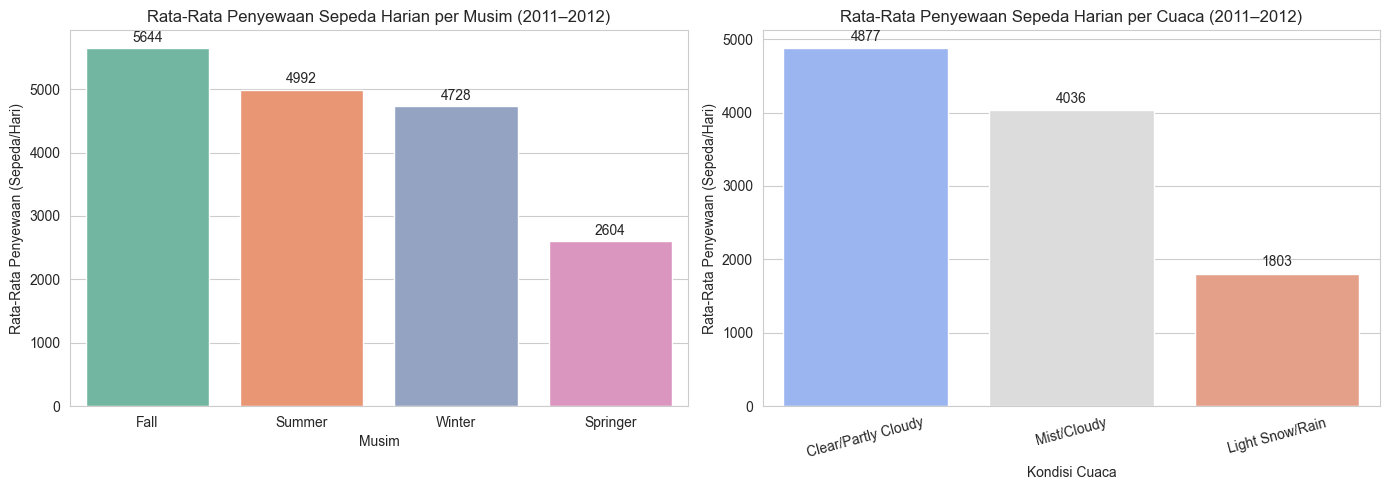

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Grafik kiri: Bar chart musim
sns.barplot(
    x='season', y='rata_rata', data=season_eda,
    ax=axes[0], palette='Set2', hue='season', legend=False
)
axes[0].set_title('Rata-Rata Penyewaan Sepeda Harian per Musim (2011–2012)', fontsize=12)
axes[0].set_xlabel('Musim')
axes[0].set_ylabel('Rata-Rata Penyewaan (Sepeda/Hari)')
for index, value in enumerate(season_eda['rata_rata']):
    axes[0].text(index, value + 100, f'{value:.0f}', ha='center', fontsize=10)

# Grafik kanan: Bar chart cuaca
sns.barplot(
    x='weathersit', y='rata_rata', data=weather_eda,
    ax=axes[1], palette='coolwarm', hue='weathersit', legend=False
)
axes[1].set_title('Rata-Rata Penyewaan Sepeda Harian per Cuaca (2011–2012)', fontsize=12)
axes[1].set_xlabel('Kondisi Cuaca')
axes[1].set_ylabel('Rata-Rata Penyewaan (Sepeda/Hari)')
axes[1].tick_params(axis='x', rotation=15)
for index, value in enumerate(weather_eda['rata_rata']):
    axes[1].text(index, value + 100, f'{value:.0f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

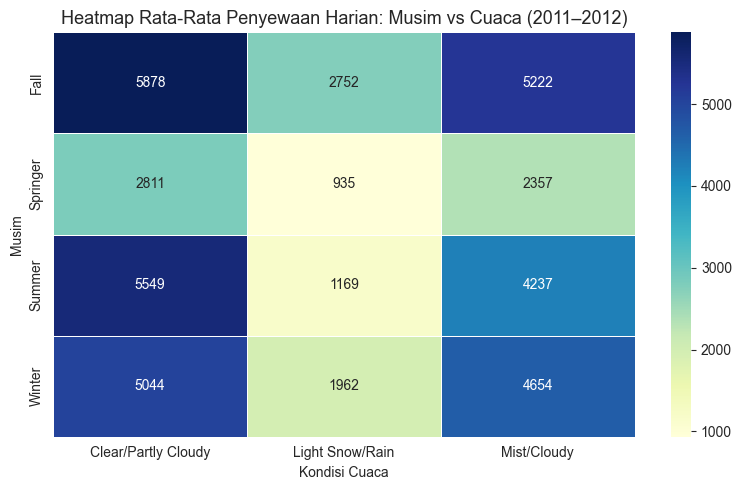

In [22]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    season_weather_eda, annot=True, fmt='.0f',
    cmap='YlGnBu', linewidths=0.5
)
plt.title('Heatmap Rata-Rata Penyewaan Harian: Musim vs Cuaca (2011–2012)', fontsize=13)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Musim')
plt.tight_layout()
plt.show()


#### Penjelasan Visualisasi Pertanyaan 1:
- Grafik batang dan *heatmap* di atas memperlihatkan bahwa rata-rata jumlah penyewa sepeda harian tertinggi sepanjang 2011–2012 terjadi pada musim **Fall (Gugur)** dengan **5.644 sepeda/hari** dan pada kondisi cuaca **Clear/Partly Cloudy (Cerah)** sebesar **4.877 sepeda/hari**.
- Sebaliknya, penyewaan terendah terjadi pada musim **Springer (Semi)** (**2.604 sepeda/hari**) dan saat cuaca **Light Snow/Rain** (**1.803 sepeda/hari**), dengan titik terendah pada kombinasi **Springer + Light Snow/Rain** sebesar **935 sepeda/hari**. Periode sepi ini menjadi waktu paling ideal untuk jadwal *maintenance* armada dan program promosi.

### Visualisasi Pertanyaan 2: Jam Puncak Rata-Rata Penyewaan Sepeda per Jam (Casual vs Registered) pada Hari Kerja Dibandingkan Hari Libur Sepanjang Tahun 2011–2012

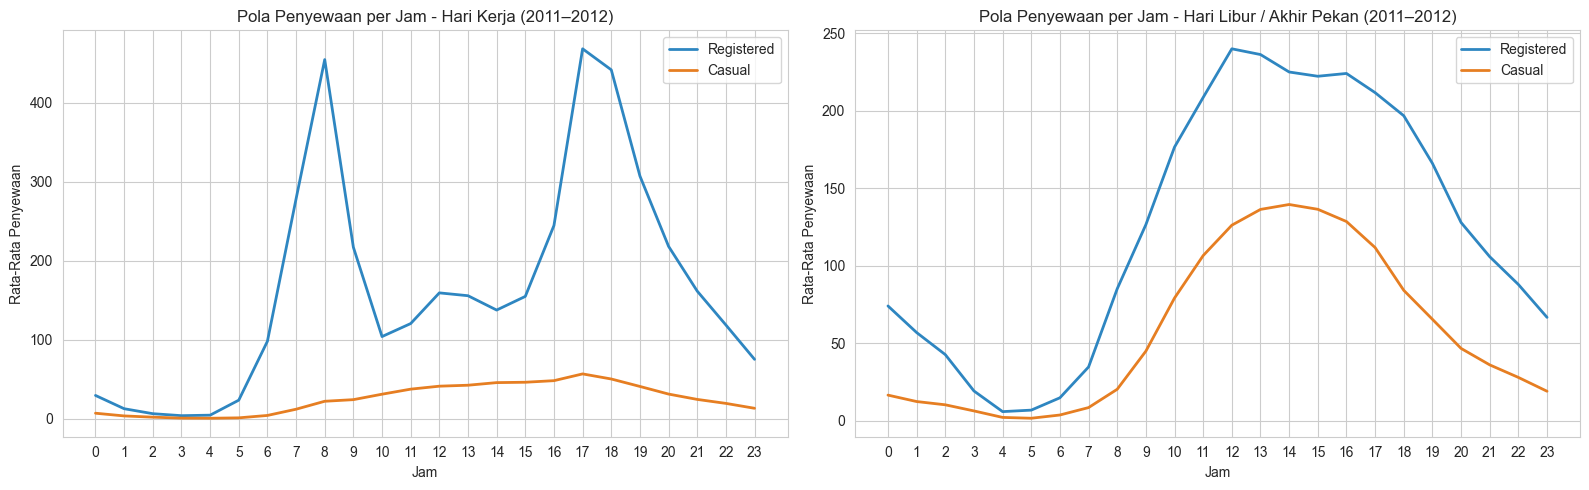

In [23]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# Grafik kiri: Hari Kerja
working_data = hourly_usage_eda[hourly_usage_eda['workingday'] == 'Working Day']
axes[0].plot(working_data['hr'], working_data['registered'], color='#2E86C1', label='Registered', linewidth=2)
axes[0].plot(working_data['hr'], working_data['casual'], color='#E67E22', label='Casual', linewidth=2)
axes[0].set_title('Pola Penyewaan per Jam - Hari Kerja (2011–2012)', fontsize=12)
axes[0].set_xlabel('Jam')
axes[0].set_ylabel('Rata-Rata Penyewaan')
axes[0].set_xticks(range(0, 24))
axes[0].legend()

# Grafik kanan: Hari Libur
holiday_data = hourly_usage_eda[hourly_usage_eda['workingday'] == 'Holiday/Weekend']
axes[1].plot(holiday_data['hr'], holiday_data['registered'], color='#2E86C1', label='Registered', linewidth=2)
axes[1].plot(holiday_data['hr'], holiday_data['casual'], color='#E67E22', label='Casual', linewidth=2)
axes[1].set_title('Pola Penyewaan per Jam - Hari Libur / Akhir Pekan (2011–2012)', fontsize=12)
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('Rata-Rata Penyewaan')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.show()

#### Penjelasan Visualisasi Pertanyaan 2:
- Grafik garis menunjukkan perbedaan pola jam puncak yang kontras antara hari kerja dan hari libur/akhir pekan sepanjang 2011–2012. Pada **Hari Kerja**, grafik membentuk dua puncak tajam (*bimodal*) pada pukul **08:00** (477 sepeda/jam) dan **17:00–18:00** (492–525 sepeda/jam) yang didominasi pengguna *registered* (89%–95%) untuk aktivitas komuter.
- Pada **Hari Libur / Akhir Pekan**, grafik membentuk satu puncak landai (*unimodal*) pada siang hingga sore hari pukul **12:00–16:00** (353–373 sepeda/jam) dengan lonjakan proporsi pengguna *casual* hingga **34,5%–38,3%**, menandakan penggunaan untuk rekreasi.

## Conclusion

### Kesimpulan Pertanyaan 1: Perbedaan Rata-Rata Jumlah Penyewa Sepeda Harian Berdasarkan Kondisi Cuaca dan Musim (2011–2012)
Berdasarkan perbandingan rata-rata deskriptif pada hasil EDA dan visualisasi data sepanjang tahun 2011–2012, dapat disimpulkan bahwa:
1. **Perbedaan Berdasarkan Musim:** Rata-rata penyewaan sepeda harian tertinggi terjadi pada musim **Fall (Gugur)** sebesar **5.644 sepeda/hari** (188 hari), diikuti **Summer (Panas)** sebesar **4.992 sepeda/hari** (184 hari) dan **Winter (Dingin)** sebesar **4.728 sepeda/hari** (178 hari). Sebaliknya, musim **Springer (Semi)** mencatatkan rata-rata terendah yaitu **2.604 sepeda/hari** (181 hari) — kurang dari separuh rata-rata musim Fall.
2. **Perbedaan Berdasarkan Kondisi Cuaca:** Rata-rata penyewaan tertinggi tercatat pada kondisi cuaca **Clear/Partly Cloudy (Cerah)** sebesar **4.877 sepeda/hari** (463 hari), diikuti **Mist/Cloudy (Berkabut/Mendung)** sebesar **4.036 sepeda/hari** (247 hari). Pada kondisi cuaca buruk **Light Snow/Rain (Hujan/Salju Ringan)** yang terjadi selama **21 hari**, rata-rata penyewaan turun drastis menjadi hanya **1.803 sepeda/hari** (lebih rendah sekitar 63% dibanding cuaca cerah).
3. **Kombinasi Musim dan Cuaca:** Rata-rata penyewaan harian tertinggi terjadi pada kombinasi musim **Fall dengan cuaca Clear/Partly Cloudy** sebesar **5.878 sepeda/hari**, sedangkan rata-rata terendah terjadi pada kombinasi musim **Springer dengan cuaca Light Snow/Rain** sebesar **935 sepeda/hari**. Periode rendah penyewa pada musim Springer dan hari hujan/salju ringan menjadi waktu paling ideal untuk menjadwalkan *maintenance* armada serta menjalankan promo tarif.

### Kesimpulan Pertanyaan 2: Jam Puncak Rata-Rata Penyewaan Sepeda per Jam (Casual vs Registered) pada Hari Kerja vs Hari Libur (2011–2012)
Berdasarkan hasil EDA dan visualisasi tren per jam sepanjang tahun 2011–2012, dapat disimpulkan bahwa:
1. **Pada Hari Kerja (*Working Day*):**
   - Total penyewaan membentuk pola **bimodal** (dua puncak tajam) pada pukul **08:00** (**477,0 sepeda/jam**) dan pukul **17:00–18:00** (**525,3** dan **492,2 sepeda/jam**).
   - **Jam puncak pengguna *registered*:** Terjadi pada sore hari pukul **17:00** (**468,4 sepeda/jam**, proporsi **89,2%**) dan **18:00** (**441,8 sepeda/jam**, proporsi **89,8%**), serta pagi hari pukul **08:00** (**454,7 sepeda/jam**, proporsi **95,3%**), yang menunjukkan dominasi penggunaan untuk aktivitas komuter rutin.
   - **Jam puncak pengguna *casual*:** Terjadi pada sore hari pukul **17:00** (**56,9 sepeda/jam**, proporsi **10,8%**).
2. **Pada Hari Libur / Akhir Pekan (*Holiday/Weekend*):**
   - Total penyewaan membentuk pola **unimodal** dengan puncak pada siang hingga sore hari pukul **12:00–16:00** (**352,7–372,7 sepeda/jam**).
   - **Jam puncak pengguna *registered*:** Terjadi pada siang hari pukul **12:00** (**240,0 sepeda/jam**, proporsi **65,5%**) dan pukul **13:00** (**236,3 sepeda/jam**, proporsi **63,4%**).
   - **Jam puncak pengguna *casual*:** Terjadi pada siang hari pukul **14:00** (**139,6 sepeda/jam**, proporsi **38,3%**), diikuti pukul **15:00** (**136,5 sepeda/jam**, **38,0%**) dan pukul **13:00** (**136,4 sepeda/jam**, **36,6%**), yang menandakan lonjakan penggunaan untuk rekreasi.

## Rekomendasi & Action Items

Berdasarkan kesimpulan analisis, berikut adalah rekomendasi tindakan konkret yang dapat diterapkan:

### 1. Penjadwalan Maintenance dan Optimalisasi Armada Berdasarkan Musim & Cuaca
- **Action:** Jadwalkan pemeliharaan (*maintenance*) besar armada sepeda pada musim **Springer (Semi)** (rata-rata terendah **2.604 sepeda/hari**) dan saat prakiraan cuaca **Light Snow/Rain** (**1.803 sepeda/hari**) agar tidak mengganggu kapasitas layanan saat permintaan puncak.
- **Action:** Maksimalkan kesiapan unit sepeda operasional pada musim **Fall (Gugur)** (**5.644 sepeda/hari**) dan **Summer (Panas)** (**4.992 sepeda/hari**), khususnya pada hari cerah (**4.877 sepeda/hari**).

### 2. Strategi Promosi pada Periode Sepi Penyewa
- **Action:** Luncurkan program promo diskon tarif atau poin loyalitas khusus selama musim **Springer** dan pada hari mendung/hujan ringan untuk mendorong tingkat penyewaan di periode sepi.

### 3. Pengaturan Alokasi Distribusi Sepeda di Stasiun Berdasarkan Jam Puncak
- **Action:** Pada **Hari Kerja**, lakukan *rebalancing* (pengisian ulang stok sepeda) di stasiun kawasan permukiman sebelum pukul **08:00** (puncak pagi *registered* **454,7 sepeda/jam**) dan di stasiun kawasan perkantoran/kampus sebelum pukul **17:00–18:00** (puncak sore *registered* **468,4 sepeda/jam** & *casual* **56,9 sepeda/jam**).
- **Action:** Pada **Hari Libur / Akhir Pekan**, prioritaskan alokasi distribusi sepeda di area taman, pusat rekreasi, dan jalur wisata menjelang pukul **12:00–15:00** untuk mengakomodasi puncak gabungan *registered* (**240,0 sepeda/jam** pukul 12:00) dan *casual* (**139,6 sepeda/jam** pukul 14:00).

### 4. Penargetan Kampanye Konversi Keanggotaan (*Membership*)
- **Action:** Fokuskan kampanye konversi keanggotaan (*membership*) bagi pengguna *casual* pada akhir pekan dan hari libur di rentang pukul **12:00–16:00** (saat porsi pengguna *casual* mencapai **34,5%–38,3%**), misalnya melalui promo *weekend pass* atau diskon registrasi anggota baru setelah selesai menyewa.

In [24]:
# Gabungkan kolom temp_category dan day_cluster dari day_df ke hour_df berdasarkan tanggal (dteday)
dashboard_df = hour_df.merge(
    day_df[['dteday', 'temp_category', 'day_cluster']],
    on='dteday',
    how='left'
)

# Pilih kolom yang dibutuhkan oleh dashboard agar ukuran file efisien
selected_cols = [
    'dteday', 'season', 'yr', 'hr', 'workingday',
    'weathersit', 'temp_celcius', 'temp_category',
    'day_cluster', 'casual', 'registered', 'cnt'
]
dashboard_df[selected_cols].to_csv("dashboard/main_data.csv", index=False)
print("dashboard/main_data.csv berhasil diexport! Jumlah baris:", len(dashboard_df))

dashboard/main_data.csv berhasil diexport! Jumlah baris: 17379
